# 04. Дообучение RoBERTa-base

Эксперименты 5–6: RoBERTa-base дообучается на регрессию целиком, вместе с энкодером.

5. **Только текст:** на вход подаётся описание сомелье.
6. **Текст + метаданные:** метаданные дописываются в текст:
   `Country: ... Province: ... Region: ... Variety: ... Winery: ... Taster: ... Description: ...`.
   Колонки те же, что в CatBoost-моделях, чтобы сравнение было честным.

**Устройство модели.** `RobertaForSequenceClassification` с регрессионной головой на 2 выхода: одна модель предсказывает
`points` и `log_price` сразу. Таргеты стандартизованы по train, лосс равен сумме MSE по двум таргетам.
Так нужно два прогона вместо четырёх, а представление текста общее для обоих таргетов.

**Обучение** на локальной RTX 5060 (8 ГБ): bf16 autocast, batch 32, `max_length=192` (99% отзывов короче 103 токенов,
с префиксом метаданных обрезки практически нет), AdamW с lr 2e-5 для энкодера и 1e-3 для головы, линейный warmup 6%, 3 эпохи.
Val проверяется 4 раза за эпоху, лучший по val чекпойнт сохраняется в `models/` и используется для test.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import os
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers.utils import logging as hf_logging

from src.config import TEXT_COL, POINTS_COL, LOG_PRICE_COL
from src.split import load_splits
from src.metrics import regression_metrics, log_metrics, save_predictions, results_table
from src.transformer import TrainConfig, train_regressor, predict, text_with_meta
from src.plots import set_style, save, MAIN, PALETTE, TEXT_MUTED

assert torch.cuda.is_available(), "Нужна CUDA-сборка torch, см. README"
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
set_style()
train, val, test = load_splits()
TARGETS = [POINTS_COL, LOG_PRICE_COL]
print(torch.cuda.get_device_name(0))
print(f"train {len(train):,}, val {len(val):,}, test {len(test):,}")

NVIDIA GeForce RTX 5060
train 89,253, val 11,157, test 11,157


In [2]:
def evaluate(experiment, target, y_pred):
    # Метрики на test: пишет их в metrics.csv, сохраняет предсказания и возвращает dict.
    y_true = test[target]
    m = regression_metrics(y_true, y_pred)
    log_metrics(experiment, target, m)
    save_predictions(experiment, target, test.index, y_true, y_pred)
    return m

cfg = TrainConfig()
summary, histories = {}, {}
cfg

TrainConfig(model_name='roberta-base', max_length=192, batch_size=32, eval_batch_size=128, lr=2e-05, head_lr=0.001, weight_decay=0.01, epochs=3, warmup_ratio=0.06, evals_per_epoch=4, seed=42)

Пример входа для эксперимента 6:

In [3]:
print(text_with_meta(train.head(1)).iloc[0])

Country: US. Province: California. Region: Sta. Rita Hills. Variety: Pinot Noir. Winery: Seagrape. Taster: unknown. Description: Crisp in acidity and fine in tannins, this Pinot Noir is good now with food. It's silky and dry, with nuanced flavors of wild raspberries and cherries, cola, dried herbs and oak. Has enough balance and acidity to develop bottle complexity over the next 4-6 years.


In [4]:
def run(experiment, to_text):
    # Обучает модель на train, отбирает чекпойнт по val, считает метрики на test для обоих таргетов.
    model, tok, scaler, hist = train_regressor(
        to_text(train), train[TARGETS].values, to_text(val), val[TARGETS].values, cfg, run_name=experiment
    )
    pred = predict(model, tok, scaler, to_text(test), cfg)
    for j, t in enumerate(TARGETS):
        summary[(experiment, t)] = evaluate(experiment, t, pred[:, j])
    histories[experiment] = hist
    hist.to_csv(f"../results/{experiment}_history.csv", index=False)
    del model
    torch.cuda.empty_cache()
    print(f"пик памяти GPU {torch.cuda.max_memory_allocated() / 1e9:.1f} ГБ")
    return pd.DataFrame(summary).T.round(3)

## 1. Только текст

In [5]:
run("roberta_text", lambda df: df[TEXT_COL])

epoch 0.25  train 0.5966  val 0.9742  *  1.2 мин


epoch 0.50  train 0.4494  val 0.8167  *  2.5 мин


epoch 0.75  train 0.4155  val 0.7617  *  3.7 мин


epoch 1.00  train 0.3932  val 0.7673  5.0 мин


epoch 1.25  train 0.3538  val 0.7263  *  6.2 мин


epoch 1.50  train 0.3487  val 0.7078  *  7.5 мин


... (4 outputs left out)

epoch 2.75  train 0.2915  val 0.6791  *  13.8 мин


epoch 3.00  train 0.2895  val 0.6696  *  15.1 мин


пик памяти GPU 4.3 ГБ


RMSE    MAE     R2
roberta_text points     1.483  1.160  0.771
             log_price  0.440  0.335  0.556

## 2. Текст + метаданные в тексте

In [6]:
run("roberta_meta", text_with_meta)

epoch 0.25  train 0.5580  val 1.0339  *  1.7 мин


epoch 0.50  train 0.3664  val 0.6820  *  3.4 мин


epoch 0.75  train 0.3260  val 0.6057  *  5.0 мин


epoch 1.00  train 0.3047  val 0.5610  *  6.7 мин


epoch 1.25  train 0.2720  val 0.5509  *  8.4 мин


epoch 1.50  train 0.2634  val 0.5411  *  10.1 мин


... (4 outputs left out)

epoch 2.75  train 0.2139  val 0.5013  18.5 мин


epoch 3.00  train 0.2097  val 0.4826  *  20.2 мин


пик памяти GPU 4.4 ГБ


RMSE    MAE     R2
roberta_text points     1.483  1.160  0.771
             log_price  0.440  0.335  0.556
roberta_meta points     1.342  1.046  0.813
             log_price  0.355  0.266  0.710

## 3. Кривые обучения

MSE на val в стандартизованной шкале отдельно по таргетам (1 − MSE примерно равно R² на val). Точка отмечает выбранный чекпойнт.

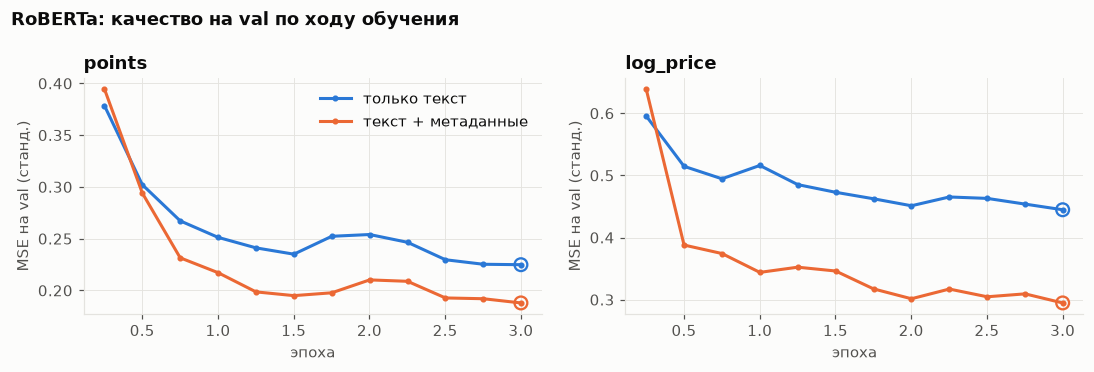

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
names = {"roberta_text": "только текст", "roberta_meta": "текст + метаданные"}
for ax, (j, t) in zip(axes, enumerate(TARGETS)):
    for (exp, h), c in zip(histories.items(), (MAIN, PALETTE[1])):
        ax.plot(h["epoch"], h[f"val_mse_{j}"], color=c, marker="o", ms=3, label=names[exp])
        b = h["val_loss"].idxmin()
        ax.scatter(h.loc[b, "epoch"], h.loc[b, f"val_mse_{j}"], s=70, facecolor="none", edgecolor=c, lw=1.5)
    ax.set_title(t)
    ax.set_xlabel("эпоха")
    ax.set_ylabel("MSE на val (станд.)")
axes[0].legend()
fig.suptitle("RoBERTa: качество на val по ходу обучения", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "roberta_learning_curves")
plt.show()

## 4. Сводка со всеми экспериментами

In [8]:
EXPS = ["mean", "meta_catboost", "tfidf_ridge", "emb_catboost", "emb_meta_catboost", "roberta_text", "roberta_meta"]
LABELS = ["среднее", "метаданные\n+ CatBoost", "TF-IDF\n+ Ridge", "эмбеддинги\n+ CatBoost",
          "эмбеддинги\n+ мета + CatBoost", "RoBERTa\nтекст", "RoBERTa\nтекст + мета"]
for t in TARGETS:
    print(t)
    display(results_table(t).loc[EXPS, ["RMSE", "MAE", "R2"]].round(3))

points


metric,RMSE,MAE,R2
experiment,,,
mean,3.100,2.539,-0.000
meta_catboost,2.207,1.739,0.493
tfidf_ridge,1.662,1.309,0.713
emb_catboost,1.914,1.512,0.619
emb_meta_catboost,1.638,1.283,0.721
roberta_text,1.483,1.160,0.771
roberta_meta,1.342,1.046,0.813


log_price


metric,RMSE,MAE,R2
experiment,,,
mean,0.659,0.527,-0.000
meta_catboost,0.378,0.275,0.672
tfidf_ridge,0.474,0.363,0.483
emb_catboost,0.492,0.379,0.444
emb_meta_catboost,0.363,0.270,0.697
roberta_text,0.440,0.335,0.556
roberta_meta,0.355,0.266,0.710


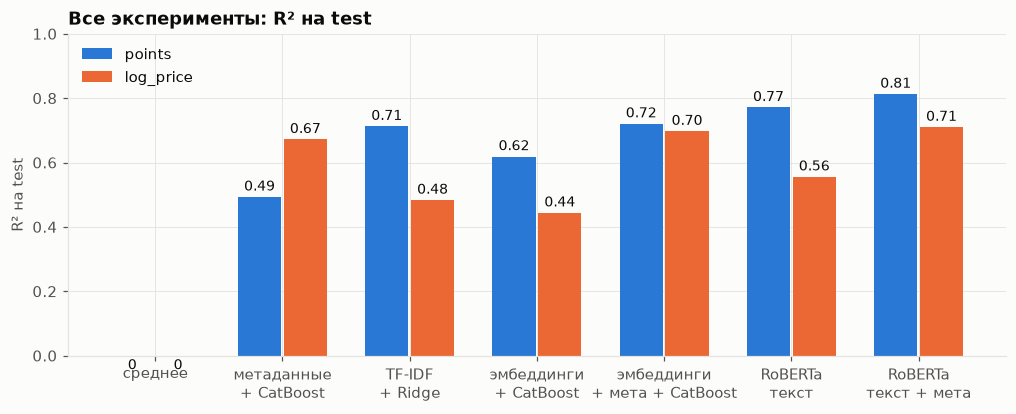

In [9]:
x = np.arange(len(EXPS))
fig, ax = plt.subplots(figsize=(11, 3.8))
for i, (t, c) in enumerate(zip(TARGETS, (MAIN, PALETTE[1]))):
    r2 = results_table(t).loc[EXPS, "R2"].values
    bars = ax.bar(x + (i - 0.5) * 0.36, r2, width=0.34, color=c, label=t)
    ax.bar_label(bars, labels=[f"{v:.2f}" if abs(v) >= 0.005 else "0" for v in r2], padding=2, fontsize=9)
ax.set_xticks(x, LABELS)
ax.set_ylabel("R² на test")
ax.set_ylim(0, 1)
ax.set_title("Все эксперименты: R² на test")
ax.legend(loc="upper left")
save(fig, "roberta_r2")
plt.show()

## 5. Выводы

| | points RMSE | points R² | log(price) MAE | log(price) R² |
|---|---|---|---|---|
| метаданные + CatBoost | 2.21 | 0.49 | 0.275 | 0.67 |
| TF-IDF + Ridge | 1.66 | 0.71 | 0.363 | 0.48 |
| эмбеддинги + мета + CatBoost | 1.64 | 0.72 | 0.270 | 0.70 |
| RoBERTa, только текст | 1.48 | 0.77 | 0.335 | 0.56 |
| RoBERTa, текст + метаданные | **1.34** | **0.81** | **0.266** | **0.71** |

**Дообучение решает то, что не смогли замороженные эмбеддинги.** RoBERTa только на тексте даёт R² 0.77 по оценке против 0.71 у TF-IDF и 0.62
у эмбеддингов + CatBoost. Энкодер подстраивается под задачу и учится замечать оценочную лексику и её контекст
(*«not particularly complex»*, *«will improve with age»*), чего не умеют ни мешок слов, ни универсальный эмбеддинг.

**Метаданные в тексте работают, без отдельной модели для категорий.** Префикс `Country: ... Winery: ... Taster: ...` даёт:
- по оценке R² 0.77 → 0.81, RMSE 1.48 → 1.34 балла: модель учитывает репутацию винодельни и шкалу дегустатора;
- по цене R² 0.56 → 0.71: лучший результат среди всех моделей, хотя преимущество над эмбеддингами + мета + CatBoost (0.70) и
  чистыми метаданными (0.67) небольшое. Цена по-прежнему в основном определяется происхождением вина, текст добавляет немного.

**Ответ на исследовательский вопрос.** Оценку можно предсказать по одному тексту с R² 0.77 (RMSE ~1.5 балла по шкале 80–100),
метаданные добавляют ещё 0.04. Цену по тексту предсказать гораздо труднее (R² 0.56), здесь основной вклад метаданных: с ними R² 0.71.

**Обучение.** 3 эпохи, ~15 мин без метаданных и ~20 мин с ними на RTX 5060, пик памяти 4.4 ГБ.
На val обе модели всё ещё немного улучшались к концу 3-й эпохи, лучший чекпойнт в обоих случаях последний.
Ещё одна эпоха, вероятно, добавила бы немного, но разрыв train/val уже растёт (train loss 0.21 против val 0.48 у модели с метаданными).

**Что дальше.** Эксперимент 7: сравнение с IACIS 2022 (R² 0.593) на их подвыборке; эксперимент 8: классификация на 2 и 4 класса.